# From emissions to warming — and the data behind one IPCC figure

### A data story on IPCC AR6 Synthesis Report, Longer Report **Figure 2.1**

The IPCC Sixth Assessment Report (AR6) closed in March 2023 with the *Synthesis Report* (SYR).
Its Longer Report **Figure 2.1** condenses the physical-science story of AR6 into four panels:
greenhouse-gas **emissions** have risen (a), **concentrations** have risen with them (b),
the planet has **warmed** by about 1.1 °C (c), and essentially **all** of that warming is attributable to human influence (d).

This notebook follows the IPCC's own data-management model — **input → intermediate → final** data — to show
where each panel comes from, which Data Distribution Centre (DDC) archives it, and how you can reuse it.
Every chart below is **redrawn from the archived final data** bundled in this project; nothing is copied from the published image.

> **How to read this page.** Text explains the provenance; charts are produced live in your browser by a
> Python kernel running in WebAssembly (JupyterLite via *notebook.link*). Open the companion
> story map `storymap/ipcc_ar6_data_journey.jGIS` to travel to the places where the data are made and kept.

## 1 · Start at the figure

**Figure 2.1 — *The causal chain from emissions to resulting warming of the climate system.***
Published at [ipcc.ch/report/ar6/syr/figures/figure-2-1](https://www.ipcc.ch/report/ar6/syr/figures/figure-2-1).

The caption ends with the IPCC's traceability tag:

> `{WGI SPM A.2.2, WGI Figure SPM.1, WGI Figure SPM.2, WGI TS2.2, WGI 2.1; WGIII Figure SPM.1, WGIII A.III.II.2.5.1}`

That tag is the map to the data:

| Panel | What it shows | Source figure in the Working Group reports |
|---|---|---|
| **(a)** | Global net anthropogenic GHG emissions 1990–2019 by gas (CO₂-FFI, CO₂-LULUCF, CH₄, N₂O, F-gases) | **WGIII Figure SPM.1**, WGIII Annex III.II.2.5.1 |
| **(b)** | Atmospheric CO₂, CH₄, N₂O concentrations (annual); panel heights scaled to each gas's warming effect | **WGI Section 2.1** (Chapter 2 Figure 2.5), WGI TS 2.2 |
| **(c)** | Global surface temperature anomaly vs 1850–1900, plus the warmest multi-century period of the last 100 000 years | **WGI Figure SPM.1** |
| **(d)** | Warming 1850–1900 → 2010–2019 attributed to human influence, GHGs, other human drivers, natural drivers, internal variability | **WGI Figure SPM.2**, WGI SPM A.2.2 |

Because the SYR is a synthesis, its figure data are a *re-publication* of Working Group data. The SYR-level records
exist only for panels (c) and (d); for (a) and (b) one must go back to the WGIII and WGI records.

## 2 · How the IPCC manages data: three tiers, four DDC partners

The IPCC Data Distribution Centre (DDC, [ipcc-data.org](https://ipcc-data.org)) is run by **DKRZ** (Germany), **CSIC-IFCA** (Spain),
**CIESIN** (Columbia University, USA) and **MetadataWorks** (UK), with **CEDA** (UK) as the archive for WGI/WGII figure data.
For AR6 the DDC classifies data as:

| Tier | Definition | Where it lives (AR6) |
|---|---|---|
| **Input data** | Observations, inventories and model simulations the authors started from | CMIP6 subset at **DKRZ** (project `IPCC-AR6_CMIP6`, 65 118 datasets, DOIs `10.26050/WDCC/AR6.*`); observational inputs cited to the originating networks |
| **Intermediate data** | Products created by authors while processing inputs (ensemble statistics, assessed ranges, regridded fields) | **DKRZ** (`IPCC-DDC_AR6_Supplements`), **CSIC** (Interactive Atlas), selected WGI figures at **CEDA** |
| **Final data** | The numbers actually plotted in a published figure | WGI/WGII: **CEDA** (`10.5285/…`, CC BY 4.0); WGIII: **IPCC Data Catalogue / MetadataWorks** (`10.48490/…`); SYR: **CIESIN-SEDAC** (`10.7927/…`) |

The next sections walk through each tier for Figure 2.1.

## 3 · Input data — where the raw numbers come from

### Panel (a): emissions inventories
* **EDGAR v6.0** (EU Joint Research Centre): fossil CO₂, CH₄, N₂O and F-gases by country and sector.
* **CO₂ from land use (LULUCF)**: mean of three bookkeeping models — **BLUE**, **Houghton & Nassikas**, **OSCAR** — from the Global Carbon Budget.
* Harmonised by the WGIII Chapter 2 team into the ESSD dataset of **Minx et al. (2021)**, archived at Zenodo
  [doi:10.5281/zenodo.6483002](https://doi.org/10.5281/zenodo.6483002) with R code on GitHub (`mcc-apsis/AR6-Emissions-trends-and-drivers`).
  GWP100 values from WGI Chapter 7 convert each gas to CO₂-equivalent.

### Panel (b): atmospheric observations
Globally averaged mole fractions assessed in WGI Chapter 2 from five networks: **NOAA GML**, **Scripps (SIO, Mauna Loa since 1958)**,
**CSIRO** (incl. Cape Grim), **AGAGE** and **UCI**. These are *not* re-hosted by the DDC; the CEDA final-data file keeps one column per network.

### Panel (c): temperature records and palaeoclimate reconstructions
* 1850–2020 global mean surface temperature: the **AR6 Chapter 2 assessed mean** of HadCRUT5, NOAAGlobalTemp-Interim, Berkeley Earth and Kadow et al. (2020).
* 1–2000 CE: **PAGES 2k Consortium (2019)** multi-proxy reconstruction.
* ~6500 years ago: Chapter 2 assessment of the mid-Holocene warm period.
* Model context (WGI SPM.1 panel b): **CMIP6** `historical`+`ssp245` and `hist-nat` ensembles, archived at DKRZ.

### Panel (d): detection & attribution inputs
* Observations: **HadCRUT4.6**.
* **CMIP6 DAMIP** experiments `hist-GHG`, `hist-aer`, `hist-nat`, `historical`+`ssp245` (Gillett et al. 2021) — all in the DKRZ `IPCC-AR6_CMIP6` archive.
* Per-driver forcing-based estimates from WGI Chapter 7.

Full tables with links: [`data/input/README.md`](data/input/README.md).

## 4 · Intermediate data — the processing layer

For most AR6 WGI figures, intermediate products (ensemble means, regional aggregates, assessed ranges) are archived at
**DKRZ** in the project [`IPCC-DDC_AR6_Supplements`](https://www.wdc-climate.de/ui/project?acronym=IPCC-DDC_AR6_Supplements)
(example: *assessed GSAT projections*, doi:10.26050/WDCC/AR6.IPCC-DDC_AR6_Sup_GSATPr) and for Chapters 2, 3, 6, 7, 8, 12 at **CEDA**
(see the *Intermediate Data* table in `IPCC-WG1/CEDA_IPCC_AR6_WGI_Figures_data`).

For Figure 2.1 specifically **no separate intermediate record exists**. Instead, the processed statistics were archived *together with the final data*:

* the CMIP6 ensemble mean and 5–95 % range behind SPM.1 are columns of `gmst_changes_model_and_obs.csv`;
* the assessed likely ranges per driver behind SPM.2 are `SPM2b.csv` and `SPM2c_data.csv`;
* the country × sector × gas table behind WGIII SPM.1 is the Zenodo workbook itself.

The *code* that turned inputs into these numbers is public: WGI figure repositories at [github.com/IPCC-WG1](https://github.com/IPCC-WG1) (mirrored on Zenodo), WGIII emissions code at `mcc-apsis`. Details: [`data/intermediate/README.md`](data/intermediate/README.md).

## 5 · Final data — the records you can download today

| Panel | Record | DOI | Host | Licence | In this project |
|---|---|---|---|---|---|
| (a) | WGIII *Data for Figure SPM.1* (Lamb et al.) | [10.48490/vfxm-tm28](https://doi.org/10.48490/vfxm-tm28) | IPCC Data Catalogue (MetadataWorks) | per record | rebuilt from the Zenodo source → `data/final/wgiii_spm1/` |
| (b) | WGI *Data for Figure 2.5* (Hall, 2023) | [10.5285/c6f19b27f8e74e98968c17c8e1f74c60](https://doi.org/10.5285/c6f19b27f8e74e98968c17c8e1f74c60) | CEDA | CC BY 4.0 | `data/final/wgi_ch2_fig2_5/` |
| (c) | WGI *Data for Figure SPM.1* v20221116 (Gillett, Kaufman, Neukom) | [10.5285/0b2759059ad6474098e40dad73e0a8ec](https://doi.org/10.5285/0b2759059ad6474098e40dad73e0a8ec) | CEDA | CC BY 4.0 | `data/final/wgi_spm1/` |
| (c) | SYR LR *Figure 2.1 (c)* v1.0.0 | [10.7927/nq55-cr83](https://doi.org/10.7927/nq55-cr83) | CIESIN / SEDAC | see record | **to add** (Excel; see `data/final/syr_fig2_1/README.md`) |
| (d) | WGI *Data for Figure SPM.2* v20210809 (Gillett, Thorne, Trewin, Szopa …) | [10.5285/c1eb6dad1598427f8f9f3eae346ece2f](https://doi.org/10.5285/c1eb6dad1598427f8f9f3eae346ece2f) | CEDA | CC BY 4.0 | `data/final/wgi_spm2/` |
| (d) | SYR LR *Figure 2.1 (d)* v1.0.0 | [10.7927/b38b-zp83](https://doi.org/10.7927/b38b-zp83) | CIESIN / SEDAC | see record | **to add** |

Below, each panel is rebuilt from these files. First a small helper for CEDA's *BADC-CSV* format
(metadata header lines, then a `data` marker, then rows until `end_data`).

In [1]:
import io, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold"})
DATA = "data/final"

def read_badc_csv(path):
    '''Read a CEDA BADC-CSV file: returns (header-metadata dict, DataFrame).'''
    meta, rows, in_data = {}, [], False
    with open(path, encoding="utf-8", errors="replace") as fh:
        for line in fh:
            parts = [p.strip() for p in line.rstrip("\n").split(",")]
            if not in_data:
                if parts[0] == "data":
                    in_data = True
                    continue
                meta.setdefault(parts[0], []).append(parts[1:])
            else:
                if parts[0] == "end_data":
                    break
                rows.append(parts)
    header_idx = rows[0]                      # first data row = column numbers
    rows = rows[1:]
    ncol = max(i for i, p in enumerate(header_idx) if p != "") + 1
    names = {}
    for ln in meta.get("long_name", []):
        if ln and ln[0].isdigit():
            names[int(ln[0])] = ln[1]
    cols = [names.get(i + 1, f"col{i+1}") for i in range(ncol)]
    df = pd.DataFrame([r[:ncol] for r in rows], columns=cols)
    df = df.apply(pd.to_numeric, errors="coerce")
    mv = meta.get("missing_value")          # e.g. ['G', '1.00E+20']
    if mv and len(mv[0]) > 1 and mv[0][1]:
        df = df.replace(float(mv[0][1]), np.nan)
    return meta, df

print("helper ready")

helper ready


### 5a · Panel (a) — Global net anthropogenic GHG emissions, 1990–2019

Rebuilt from the Minx et al. (2021) workbook (the input to WGIII Figure SPM.1): global totals by gas in Gt CO₂-eq yr⁻¹ using AR6 GWP100,
CO₂-LULUCF as the three-model mean. WGIII reported **59 ± 6.6 Gt CO₂-eq in 2019**, 12 % above 2010 and 54 % above 1990.

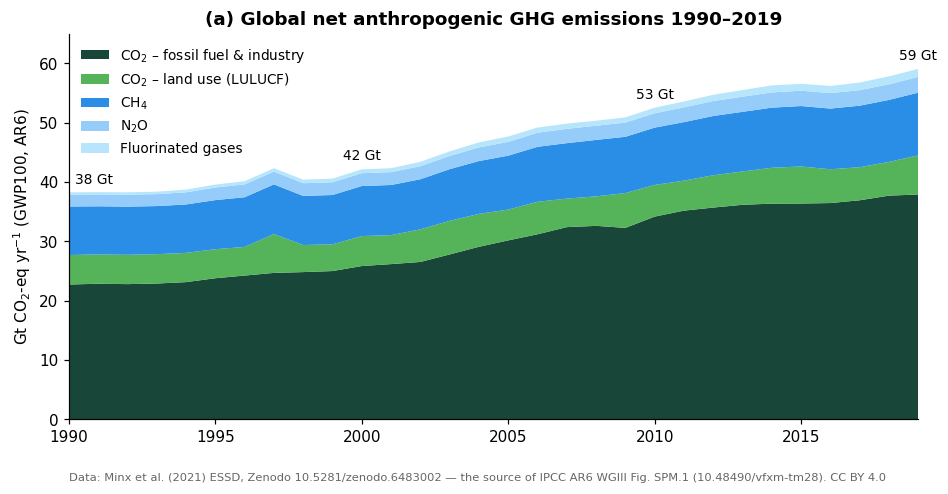

2019 total: 59.1 Gt CO2-eq  |  change vs 1990: +54%  |  vs 2010: +12%
2019 shares (%): {'CO2_FFI': 64.2, 'CO2_LULUCF': 11.2, 'CH4': 17.9, 'N2O': 4.5, 'F_gases': 2.3}


In [2]:
em = pd.read_csv(f"{DATA}/wgiii_spm1/global_ghg_emissions_by_gas_1970-2019.csv", comment="#", index_col="year")
em = em.loc[1990:2019]

order  = ["CO2_FFI", "CO2_LULUCF", "CH4", "N2O", "F_gases"]
labels = {"CO2_FFI": "CO$_2$ – fossil fuel & industry", "CO2_LULUCF": "CO$_2$ – land use (LULUCF)",
          "CH4": "CH$_4$", "N2O": "N$_2$O", "F_gases": "Fluorinated gases"}
colors = {"CO2_FFI": "#0b3d2e", "CO2_LULUCF": "#4caf50", "CH4": "#1e88e5", "N2O": "#90caf9", "F_gases": "#b3e5fc"}

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.stackplot(em.index, [em[c] for c in order], labels=[labels[c] for c in order],
             colors=[colors[c] for c in order], alpha=0.95)
tot = em["GHG_total"]
for yr in (1990, 2000, 2010, 2019):
    ax.annotate(f"{tot[yr]:.0f} Gt", (yr, tot[yr]), textcoords="offset points", xytext=(4 if yr == 1990 else 0, 6),
                ha="left" if yr == 1990 else "center", fontsize=9)
ax.set_xlim(1990, 2019); ax.set_ylim(0, 65)
ax.set_ylabel("Gt CO$_2$-eq yr$^{-1}$ (GWP100, AR6)")
ax.set_title("(a) Global net anthropogenic GHG emissions 1990–2019")
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.text(0, -0.16, "Data: Minx et al. (2021) ESSD, Zenodo 10.5281/zenodo.6483002 — the source of IPCC AR6 WGIII Fig. SPM.1 (10.48490/vfxm-tm28). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

share = (em.loc[2019, order] / tot[2019] * 100).round(1)
print("2019 total: {:.1f} Gt CO2-eq  |  change vs 1990: {:+.0f}%  |  vs 2010: {:+.0f}%".format(
      tot[2019], (tot[2019]/tot[1990]-1)*100, (tot[2019]/tot[2010]-1)*100))
print("2019 shares (%):", share.to_dict())

### 5b · Panel (b) — Atmospheric concentrations of CO₂, CH₄ and N₂O

From the CEDA record for WGI Figure 2.5 (NOAA GML series shown; the file also holds SIO, CSIRO, AGAGE and UCI).
As in the SYR figure, the **height of each sub-panel is scaled to the gas's assessed contribution to warming** (1850–1900 → 2010–2019),
taken from the WGI SPM.2 panel (c) data: CO₂ ≈ 0.79 °C, CH₄ ≈ 0.51 °C, N₂O ≈ 0.09 °C.

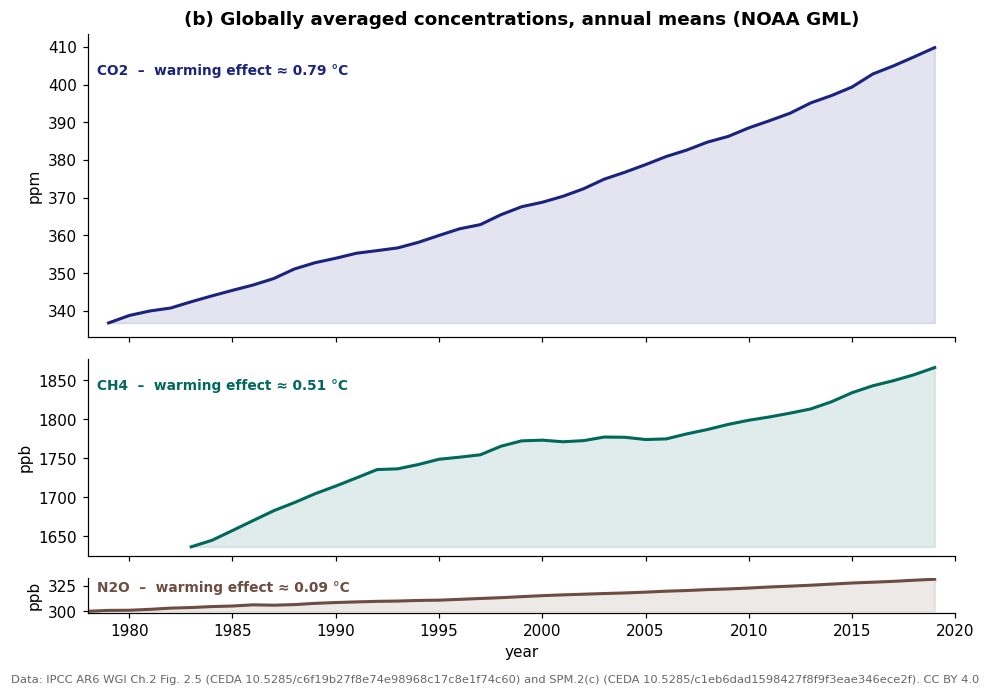

CO2: 1979 = 336.8 ppm  →  2019 = 409.8 ppm
CH4: 1983 = 1636.3 ppb  →  2019 = 1866.5 ppb
N2O: 1978 = 300.0 ppb  →  2019 = 331.9 ppb


In [3]:
conc = pd.read_csv(f"{DATA}/wgi_ch2_fig2_5/Data_Figure_2.5.csv", skiprows=3)  # 3 comment lines, one of them quoted
drivers = pd.read_csv(f"{DATA}/wgi_spm2/SPM2c_data.csv").set_index("Driver")
eff = {"CO2": drivers.loc["Carbon dioxide (CO_2)", "total GSAT effect"],
       "CH4": drivers.loc["Methane (CH_4)", "total GSAT effect"],
       "N2O": drivers.loc["Nitrous oxide (N_2O)", "total GSAT effect"]}

series = {"CO2": ("NOAA_CO2_xdate", "NOAA_CO2", "ppm", "#1a237e"),
          "CH4": ("NOAA_CH4_xdate", "NOAA_CH4", "ppb", "#00695c"),
          "N2O": ("NOAA_N2O_xdate", "NOAA_N2O", "ppb", "#6d4c41")}

fig, axes = plt.subplots(3, 1, figsize=(9, 6.2), sharex=True,
                         gridspec_kw={"height_ratios": [eff["CO2"], eff["CH4"], eff["N2O"]]})
for ax, gas in zip(axes, ["CO2", "CH4", "N2O"]):
    xcol, ycol, unit, col = series[gas]
    d = conc[[xcol, ycol]].dropna()
    annual = d.groupby(d[xcol].astype(int))[ycol].mean()
    ax.plot(annual.index, annual.values, color=col, lw=2)
    ax.fill_between(annual.index, annual.min(), annual.values, color=col, alpha=0.12)
    ax.set_ylabel(unit)
    ax.text(0.01, 0.9, f"{gas}  –  warming effect ≈ {eff[gas]:.2f} °C",
            transform=ax.transAxes, fontsize=9, fontweight="bold", color=col, va="top")
    ax.set_xlim(1978, 2020)
axes[0].set_title("(b) Globally averaged concentrations, annual means (NOAA GML)")
axes[-1].set_xlabel("year")
fig.text(0.01, -0.01, "Data: IPCC AR6 WGI Ch.2 Fig. 2.5 (CEDA 10.5285/c6f19b27f8e74e98968c17c8e1f74c60) and SPM.2(c) (CEDA 10.5285/c1eb6dad1598427f8f9f3eae346ece2f). CC BY 4.0",
         fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

for gas in ["CO2", "CH4", "N2O"]:
    xcol, ycol, unit, _ = series[gas]
    d = conc[[xcol, ycol]].dropna()
    a = d.groupby(d[xcol].astype(int))[ycol].mean()
    print(f"{gas}: {a.index.min()} = {a.iloc[0]:.1f} {unit}  →  2019 = {a.loc[2019]:.1f} {unit}")

### 5c · Panel (c) — Global surface temperature change since 1850–1900

From the CEDA record for WGI Figure SPM.1: the annual observed series (Chapter 2 assessed mean) and the decadally smoothed curve,
with the assessed temperature of the **warmest multi-century period in at least the last 100 000 years (~6500 years ago)** shown as a bar.
The SYR records this panel separately as *SYR LR Figure 2.1 (c)* (doi:10.7927/nq55-cr83).

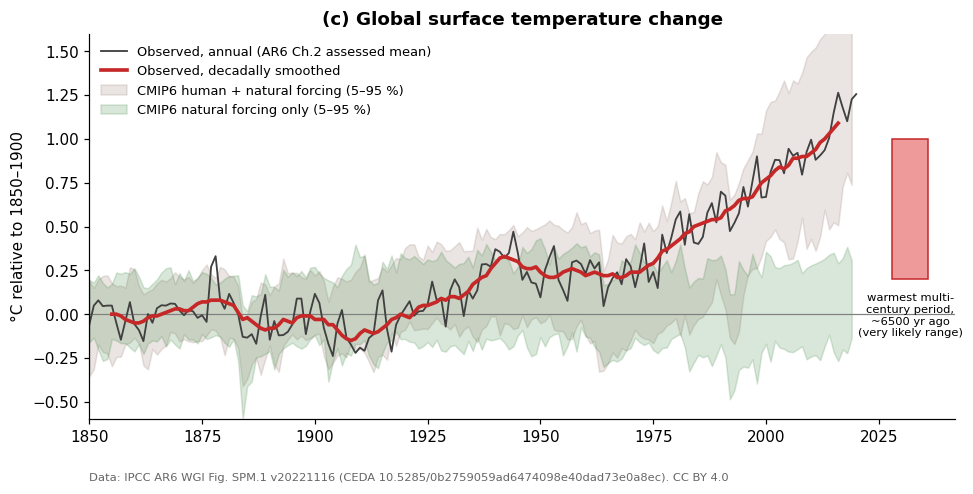

2011–2020 mean observed anomaly: 1.09 °C
Mid-Holocene very likely range: 0.2–1.0 °C


In [4]:
_, gmst = read_badc_csv(f"{DATA}/wgi_spm1/gmst_changes_model_and_obs.csv")
_, obs_dec = read_badc_csv(f"{DATA}/wgi_spm1/SPM1_1850-2020_obs.csv")
_, holo = read_badc_csv(f"{DATA}/wgi_spm1/spm1_6500_recon.csv")
gmst = gmst.set_index("Year").sort_index()
obs_dec = obs_dec.set_index("Year").sort_index()
holo_lo, holo_hi = holo.iloc[0, 1], holo.iloc[0, 2]

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.axhline(0, color="0.5", lw=0.8)
ax.bar(1850, 0, 0)  # keep x origin
ax.plot(gmst.index, gmst["gsta_black_obs"], color="0.25", lw=1.2, label="Observed, annual (AR6 Ch.2 assessed mean)")
ax.plot(obs_dec.index, obs_dec["Temperature"], color="#c62828", lw=2.4, label="Observed, decadally smoothed")
ax.fill_between(gmst.index, gmst["gsta_brown_shading_bottom_hist_ssp245"], gmst["gsta_brown_shading_top_hist_ssp245"],
                color="#8d6e63", alpha=0.18, label="CMIP6 human + natural forcing (5–95 %)")
ax.fill_between(gmst.index, gmst["gsta_green_shading_bottom_hist_nat"], gmst["gsta_green_shading_top_hist_nat"],
                color="#2e7d32", alpha=0.18, label="CMIP6 natural forcing only (5–95 %)")
# Holocene bar at the right
ax.bar(2032, holo_hi - holo_lo, bottom=holo_lo, width=8, color="#ef9a9a", edgecolor="#c62828")
ax.text(2032, holo_lo - 0.08, "warmest multi-\ncentury period,\n~6500 yr ago\n(very likely range)", ha="center", va="top", fontsize=7.5)
ax.set_xlim(1850, 2042); ax.set_ylim(-0.6, 1.6)
ax.set_ylabel("°C relative to 1850–1900")
ax.set_title("(c) Global surface temperature change")
ax.legend(loc="upper left", frameon=False, fontsize=8.5)
ax.text(0, -0.16, "Data: IPCC AR6 WGI Fig. SPM.1 v20221116 (CEDA 10.5285/0b2759059ad6474098e40dad73e0a8ec). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

print("2011–2020 mean observed anomaly: {:.2f} °C".format(gmst.loc[2011:2020, "gsta_black_obs"].mean()))
print("Mid-Holocene very likely range: {:.1f}–{:.1f} °C".format(holo_lo, holo_hi))

### 5d · Panel (d) — Humans are responsible

From the CEDA record for WGI Figure SPM.2 panel (b): warming 1850–1900 → 2010–2019 observed (HadCRUT4.6) and attributed to each driver
from CMIP6 DAMIP simulations. Bars are the best estimate (total human influence) or mid-point of the likely range; whiskers are the **likely** range.
The SYR records this panel separately as *SYR LR Figure 2.1 (d)* (doi:10.7927/b38b-zp83).

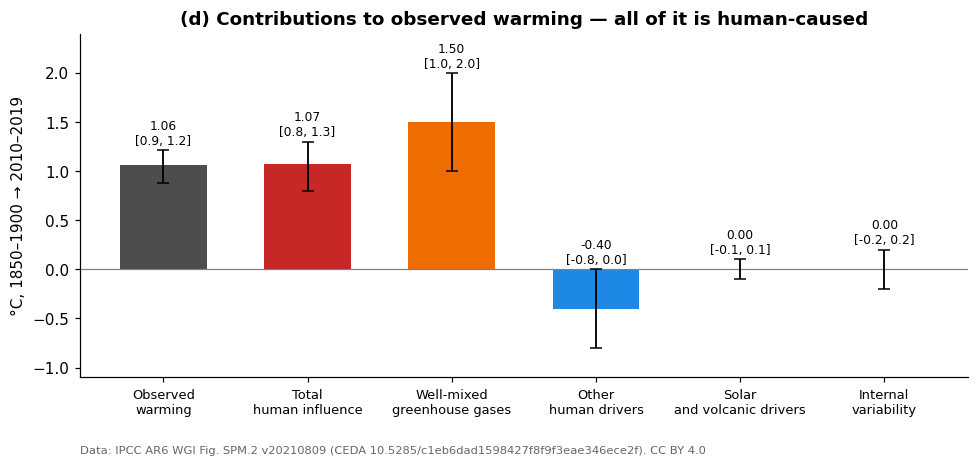

In [5]:
spm2a = pd.read_csv(f"{DATA}/wgi_spm2/SPM2a.csv", index_col=0).iloc[:, 0]
spm2b = pd.read_csv(f"{DATA}/wgi_spm2/SPM2b.csv", index_col=0)
spm2b.columns = [c.strip() for c in spm2b.columns]
spm2b.index = [i.strip() for i in spm2b.index]

cats = ["Observed warming", "Total human influence", "Well-mixed greenhouse gases",
        "Other human drivers", "Solar and volcanic drivers", "Internal variability"]
centre = [spm2a["Mean/Centre"]] + [spm2b.loc["Mean/Centre", c] for c in cats[1:]]
lo     = [spm2a["Bottom"]]      + [spm2b.loc["Bottom", c]      for c in cats[1:]]
hi     = [spm2a["Top"]]         + [spm2b.loc["Top", c]         for c in cats[1:]]
cols = ["0.3", "#c62828", "#ef6c00", "#1e88e5", "#43a047", "#8e24aa"]

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.axhline(0, color="0.5", lw=0.8)
ax.bar(range(6), centre, color=cols, width=0.6)
ax.errorbar(range(6), centre, yerr=[np.array(centre) - np.array(lo), np.array(hi) - np.array(centre)],
            fmt="none", ecolor="k", capsize=4, lw=1.2)
for i, (c, l, h) in enumerate(zip(centre, lo, hi)):
    ax.text(i, h + 0.06, f"{c:.2f}\n[{l:.1f}, {h:.1f}]", ha="center", fontsize=8)
ax.set_xticks(range(6)); ax.set_xticklabels([c.replace(" ", "\n", 1) for c in cats], fontsize=8.5)
ax.set_ylim(-1.1, 2.4); ax.set_ylabel("°C, 1850–1900 → 2010–2019")
ax.set_title("(d) Contributions to observed warming — all of it is human-caused")
ax.text(0, -0.22, "Data: IPCC AR6 WGI Fig. SPM.2 v20210809 (CEDA 10.5285/c1eb6dad1598427f8f9f3eae346ece2f). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

### 5e · The whole chain in one view

Putting the four redrawn panels together reproduces the logic of SYR Figure 2.1 from open data alone.

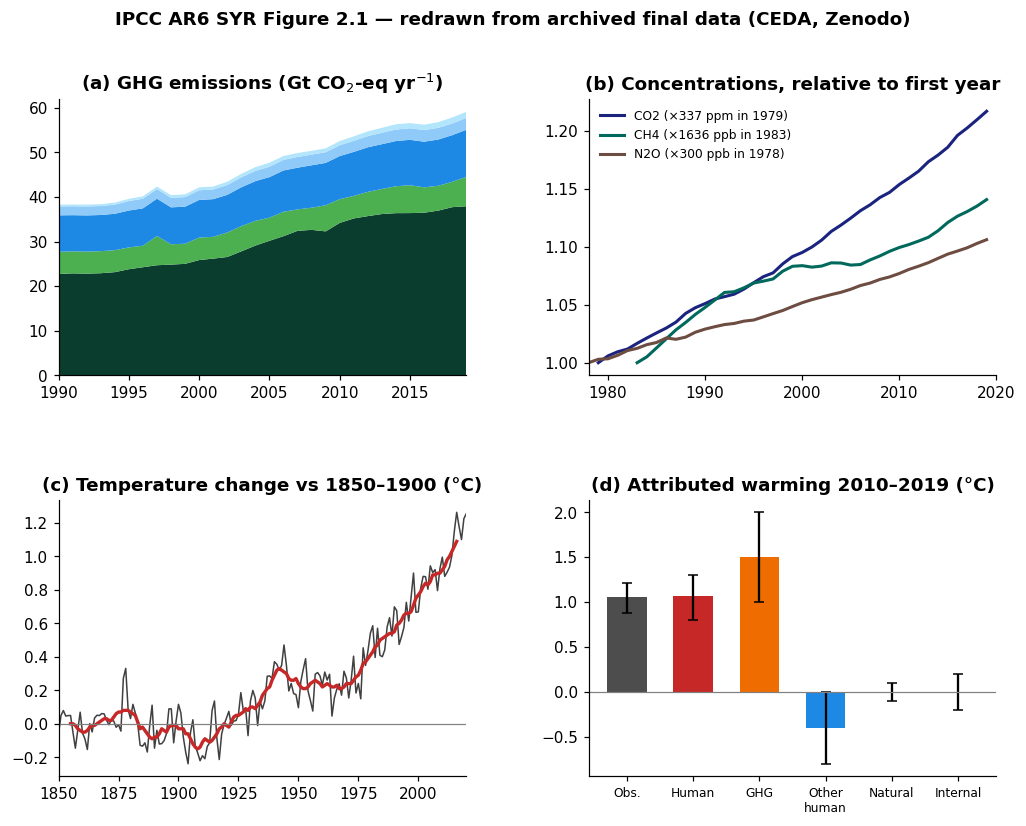

In [6]:
fig = plt.figure(figsize=(11, 8))
gs = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.3)

# (a)
ax = fig.add_subplot(gs[0, 0])
ax.stackplot(em.index, [em[c] for c in order], colors=[colors[c] for c in order])
ax.set_title("(a) GHG emissions (Gt CO$_2$-eq yr$^{-1}$)"); ax.set_xlim(1990, 2019)

# (b)
ax = fig.add_subplot(gs[0, 1])
for gas, (xcol, ycol, unit, col) in series.items():
    d = conc[[xcol, ycol]].dropna(); a = d.groupby(d[xcol].astype(int))[ycol].mean()
    ax.plot(a.index, a / a.iloc[0], color=col, lw=2, label=f"{gas} (×{a.iloc[0]:.0f} {unit} in {a.index.min()})")
ax.set_title("(b) Concentrations, relative to first year"); ax.legend(frameon=False, fontsize=8); ax.set_xlim(1978, 2020)

# (c)
ax = fig.add_subplot(gs[1, 0])
ax.plot(gmst.index, gmst["gsta_black_obs"], color="0.25", lw=1)
ax.plot(obs_dec.index, obs_dec["Temperature"], color="#c62828", lw=2.2)
ax.axhline(0, color="0.5", lw=0.8); ax.set_title("(c) Temperature change vs 1850–1900 (°C)"); ax.set_xlim(1850, 2020)

# (d)
ax = fig.add_subplot(gs[1, 1])
ax.bar(range(6), centre, color=cols, width=0.6)
ax.errorbar(range(6), centre, yerr=[np.array(centre) - np.array(lo), np.array(hi) - np.array(centre)], fmt="none", ecolor="k", capsize=3)
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xticks(range(6)); ax.set_xticklabels(["Obs.", "Human", "GHG", "Other\nhuman", "Natural", "Internal"], fontsize=8)
ax.set_title("(d) Attributed warming 2010–2019 (°C)")

fig.suptitle("IPCC AR6 SYR Figure 2.1 — redrawn from archived final data (CEDA, Zenodo)", fontweight="bold")
plt.show()

## 6 · The SYR-level records (to be completed)

The IPCC Data Catalogue holds SYR-level copies of panels (c) and (d), hosted by CIESIN/SEDAC as Excel workbooks:

* **SYR LR Figure 2.1 (c)** — dataset 8498, [doi:10.7927/nq55-cr83](https://doi.org/10.7927/nq55-cr83)
* **SYR LR Figure 2.1 (d)** — dataset 8493, [doi:10.7927/b38b-zp83](https://doi.org/10.7927/b38b-zp83)

They could not be downloaded automatically (browser-only hosting). Once saved as CSV in `data/final/syr_fig2_1/`,
the cell below compares them with the WGI values plotted above.

In [7]:
import os
syr_c = f"{DATA}/syr_fig2_1/syr_lr_fig2_1c.csv"
syr_d = f"{DATA}/syr_fig2_1/syr_lr_fig2_1d.csv"
if os.path.exists(syr_c) and os.path.exists(syr_d):
    display(pd.read_csv(syr_c).head()); display(pd.read_csv(syr_d).head())
else:
    print("SYR workbooks not yet added – see data/final/syr_fig2_1/README.md (TODO).")

SYR workbooks not yet added – see data/final/syr_fig2_1/README.md (TODO).


## 7 · How to use the data yourself

1. **Start from the caption.** The `{WGI SPM.1 …}` tag names the source figures; every AR6 figure page on ipcc.ch carries one.
2. **Find the final data record.**
   * WGI / WGII → CEDA catalogue, search "data for Figure …" (`10.5285/…`), or the index at `IPCC-WG1/CEDA_IPCC_AR6_WGI_Figures_data`.
   * WGIII → IPCC Data Catalogue (`ipcc-browser.ipcc-data.org`, `10.48490/…`).
   * SYR → IPCC Data Catalogue, hosted by CIESIN/SEDAC (`10.7927/…`).
3. **Read the README and licence shipped with the record** — CEDA files are BADC-CSV with embedded metadata; the helper above parses them.
4. **Trace back to inputs** when you need more than what is plotted: CMIP6 at DKRZ (`IPCC-AR6_CMIP6`), intermediate products at DKRZ (`IPCC-DDC_AR6_Supplements`) or CEDA, observations at the originating networks.
5. **Cite twice**: the dataset DOI *and* the report component (e.g. `IPCC, 2021: Summary for Policymakers … doi:10.1017/9781009157896.001`).
6. **Respect the licences**: CEDA data are CC BY 4.0; figure *images* fall under the IPCC copyright policy, so redraw from data as done here.

### Open questions / things to complete
* Add the two SYR Excel workbooks (panels c, d) and confirm the DOI for panel (d) on the SEDAC landing page.
* Record any Figure-2.1-relevant entries from the DKRZ `IPCC-DDC_AR6_Supplements` list.
* The CEDA "SYR dataset collection" record exists but was unpublished when checked (2026-10-13).

---
*Built with notebook.link (JupyterLite + xeus-python) · data © IPCC authors / CEDA / Zenodo contributors, CC BY 4.0 · story map: `storymap/ipcc_ar6_data_journey.jGIS`*